In [11]:
import ollama

import utils
from prompts import BOUNDING_BOX_GENERATOR_SYSTEM_PROMPT
from utils import visualize_segmentation, generate_bounding_box_for_image
import json

First tests for vlm

In [2]:
client = ollama.Client(host='192.168.178.23')
system_prompt = ("Describe what is drawn on the photo")
response = client.chat(
    model='qwen2.5vl:7b',
    # model='minicpm-v:latest',
    messages = [
        {
            'role': 'system',
            'content': system_prompt,
        },
        {
            'role': 'user',
            'content': "Explain carefully what you see",
            'images': ["test_images/test_image_1.jpg"]
        }
    ],
    format='json',
    options={'temperature':0.1}
)
content = response['message']['content']
content

'{  \n  "description": "The image depicts an animated character with a square, textured body resembling a piece of fried food, possibly chicken. The character has a large, round head with large, expressive eyes and a small, beak-like nose. It has white wings and is sitting on a horse, which is partially visible in the foreground. In the background, there is a grassy field with colorful flowers and two other animated characters: a green one and a red one, both with a bird-like appearance. The setting appears to be outdoors, with trees and a partly cloudy sky in the distance. The image is labeled as AI-generated."  \n}'

Formalize in a function

In [3]:
def generate_bounding_box_for_image(ollama_host, image_path, user_prompt):
    """
    Note: image size should be multiple of 28
    :param ollama_host:
    :param image_path:
    :param user_prompt:
    :return:
    """
    client = ollama.Client(host=ollama_host)
    system_prompt = (BOUNDING_BOX_GENERATOR_SYSTEM_PROMPT)
    response = client.chat(
        model='qwen2.5vl:7b',
        messages = [
            {
                'role': 'system',
                'content': system_prompt,
            },
            {
                'role': 'user',
                'content': f"{user_prompt}",
                'images': [image_path]
            }
        ],
        format='json',
        options={'temperature':0.1}
    )
    content = response['message']['content']
    return content

Verification of the performance on the actual bounding box generation task

{"bbox_2d": [322, 412, 512, 501]}
Image size (H, W, C): (1280, 718, 3)


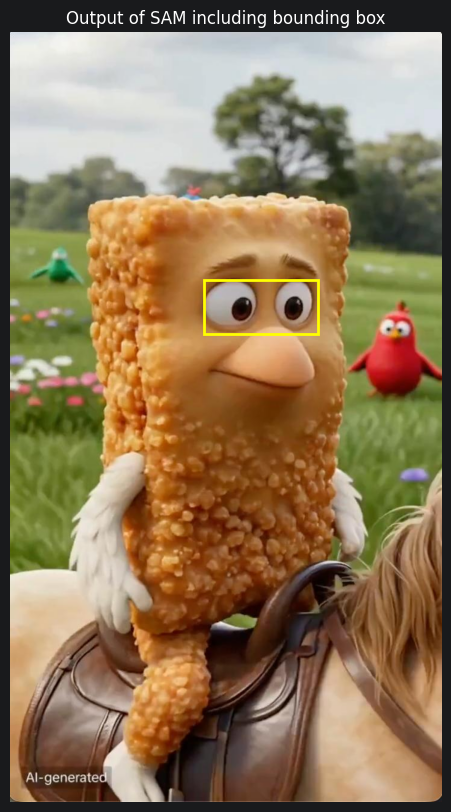

In [4]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "two eyes"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{"bbox_2d": [569, 447, 728, 611]}
Image size (H, W, C): (1280, 718, 3)


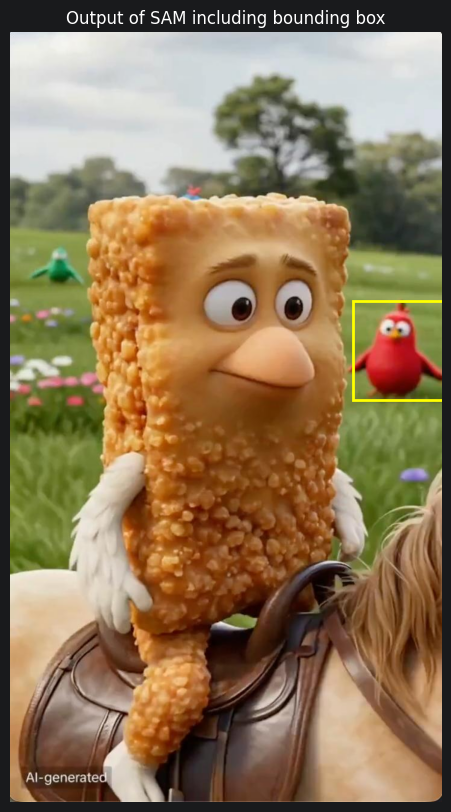

In [5]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "red chicken"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{"bbox_2d": [295, 255, 322, 277] }
Image size (H, W, C): (1280, 718, 3)


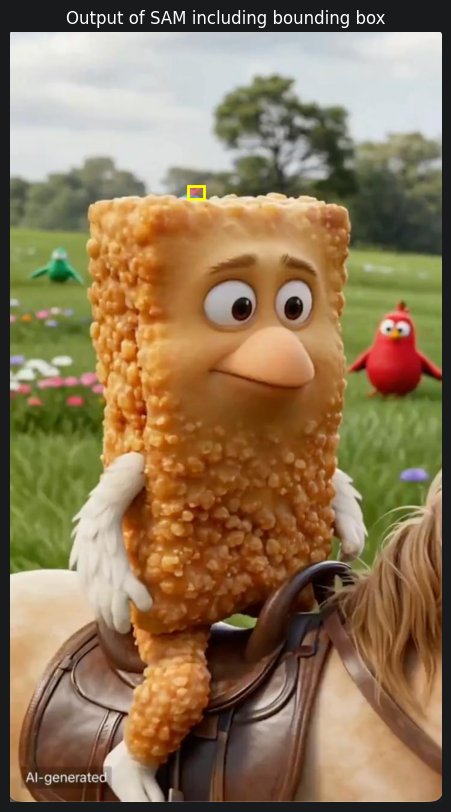

In [6]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "airplane"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

{"bbox_2d": [0, 462, 158, 633]}
Image size (H, W, C): (1280, 718, 3)


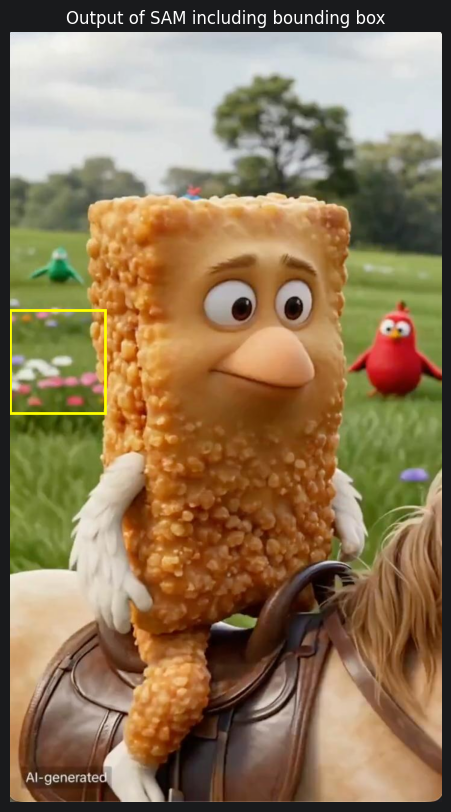

In [7]:
image_path = "test_images/test_image_1.jpg"
user_prompt = "white flowers"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

[330, 724, 484, 926]
{"bbox_2d": [330, 724, 484, 926]}
Image size (H, W, C): (1008, 1008, 3)


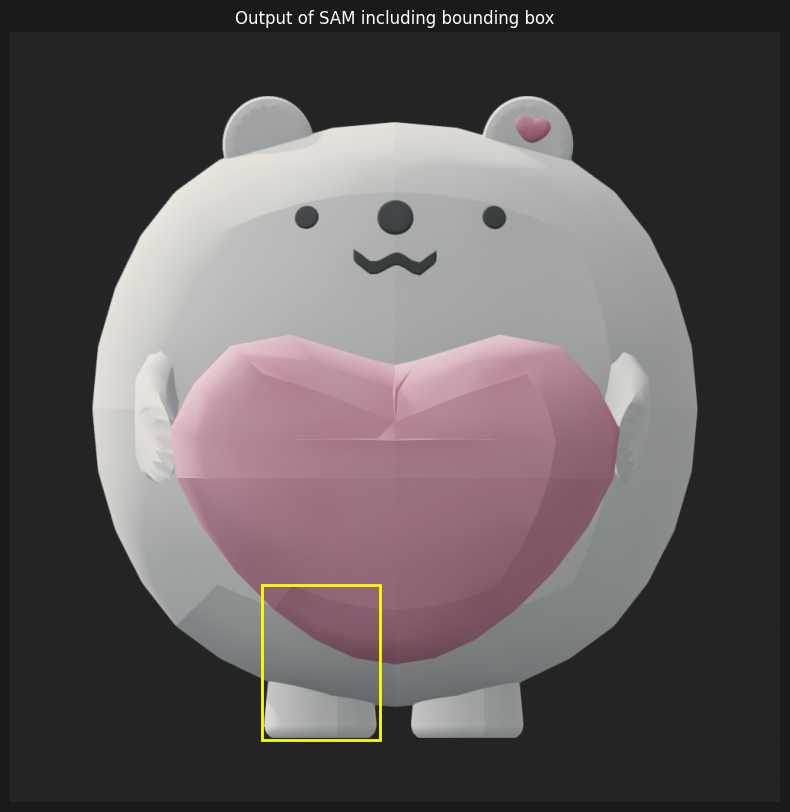

In [8]:
image_path = "test_images/test_image_2.png"
user_prompt = "left to the user leg"
json_output = generate_bounding_box_for_image('192.168.178.23', image_path, f"{user_prompt}")
data = json.loads(json_output)
four_coordinates = data['bbox_2d']
print(four_coordinates)
x1= four_coordinates[0]
y1= four_coordinates[1]
x2= four_coordinates[2]
y2= four_coordinates[3]
print(json_output)
visualize_segmentation(image_path= image_path ,mask=None,x1= x1,y1= y1,x2= x2,y2= y2)

[393, 734, 505, 818]
[393, 734, 505, 818]
Image size (H, W, C): (1008, 1008, 3)


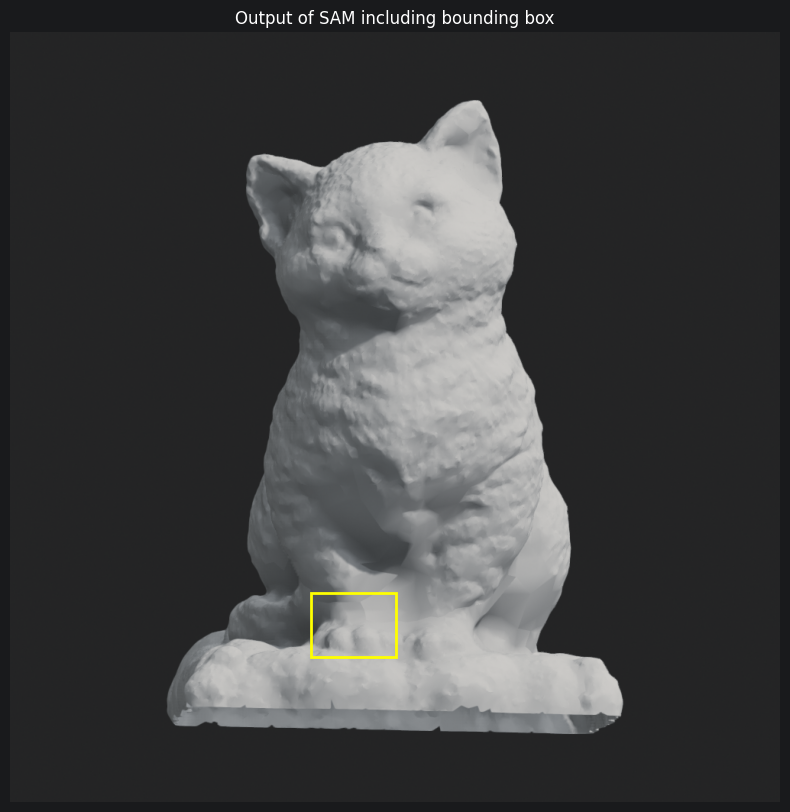

In [13]:
image_path = "test_images/test_image_3.png"
user_prompt = "paw"
bounding_box = utils.generate_bounding_box_for_image("192.168.178.23", image_path, f"{user_prompt}")
print(bounding_box)
visualize_segmentation(image_path= image_path ,mask=None,x1= bounding_box[0],y1= bounding_box[1],x2= bounding_box[2],y2= bounding_box[3])